# 高维风险 PCA 与 UMAP
同一120人、23,146基因。探索使用固定80人；预测观察固定80/40人。课堂只运行第1种排列，不根据40人的结果改变模型或基因数。原表达已是log2(1+FPKM)，不再取对数。

In [1]:
"""Single-cohort experiments; all fit operations explicitly respect patient splits.

No synthetic expression, no feature order chosen by labels. Reproduce with run_all().
"""
import os
for _k in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS','NUMBA_NUM_THREADS']:
 os.environ[_k]='1'
from pathlib import Path
import json,re,hashlib,warnings,time
import numpy as np,pandas as pd
from scipy.spatial.distance import pdist,squareform,cdist
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
threadpool_limits(1)
plt.rcParams.update({'font.family':'Microsoft YaHei','axes.unicode_minus':False,'font.size':10})
ROOT=Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
OUT=ROOT/'assets'/'pbl-high-dimension-reduction';OUT.mkdir(parents=True,exist_ok=True)
DATA=ROOT/'data';SEED=20260921
_cache=ROOT/'review'/'numba-cache';_cache.mkdir(parents=True,exist_ok=True)
os.environ['NUMBA_CACHE_DIR']=str(_cache)
COUNTS=[20,100,500,2000,5000]

import sys
sys.path.insert(0,str(ROOT/"scripts"))
from IPython.display import display, Image


In [2]:
def dump(name,obj):
 (OUT/name).write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')

def csv(name,rows):
 df=rows if isinstance(rows,pd.DataFrame) else pd.DataFrame(rows)
 df.to_csv(OUT/name,index=False,encoding='utf-8-sig');return df

def plot_save(name):
 plt.tight_layout();plt.savefig(OUT/name,dpi=160);plt.close()

def load():
 a=np.load(DATA/'cohort120.npz',allow_pickle=True)
 return {k:a[k] for k in a.files}

def dev_data(a):
 d=a['development'];return a['X'][d],a['y'][d],a['ids'][d],a['genes']
a=load()
X,y,ids,genes=dev_data(a)
assert a["X"].shape==(120,23146)
assert len(X)==80 and len(a["test"])==40
print("Shape",a["X"].shape,"seen risk counts",np.bincount(y),"unseen risk counts",np.bincount(a["y"][a["test"]]))
print(pd.read_csv(DATA/"patient-manifest.csv").head())

Shape (120, 23146) seen risk counts [53 27] unseen risk counts [26 14]
   patient_id         gsm  ...    flowcell  lane
0  SEQC_NB003  GSM1205738  ...  BD03U8ACXX    L7
1  SEQC_NB005  GSM1205740  ...  BD03U8ACXX    L7
2  SEQC_NB015  GSM1205750  ...  BC02FPACXX    L1
3  SEQC_NB017  GSM1205752  ...  BC02FPACXX    L1
4  SEQC_NB019  GSM1205754  ...  BC02FPACXX    L2

[5 rows x 18 columns]


## 课堂 Q2 距离
第1种嵌套排列的六种基因数；只比较同一80人。记录绝对距离、最近/最远距离与相对差异。

20 mean 5.840479406663735 near 3.2475824981154915 far 9.07818502409032 contrast 1.986085674256011
100 mean 13.318108539288563 near 8.756131404486203 far 19.73070971048235 contrast 1.3331743263365727
500 mean 30.231358602599947 near 21.693330712509013 far 41.1559172686329 contrast 0.9395457408215802
2000 mean 60.20314253239659 near 44.348478053849725 far 81.283161290259 contrast 0.8667016074516903
5000 mean 95.19763918513719 near 70.58474277716388 far 128.73529918767764 contrast 0.8561239314740021
23146 mean 204.33227205410506 near 151.1557198894809 far 275.26092972912676 contrast 0.8544111818282882


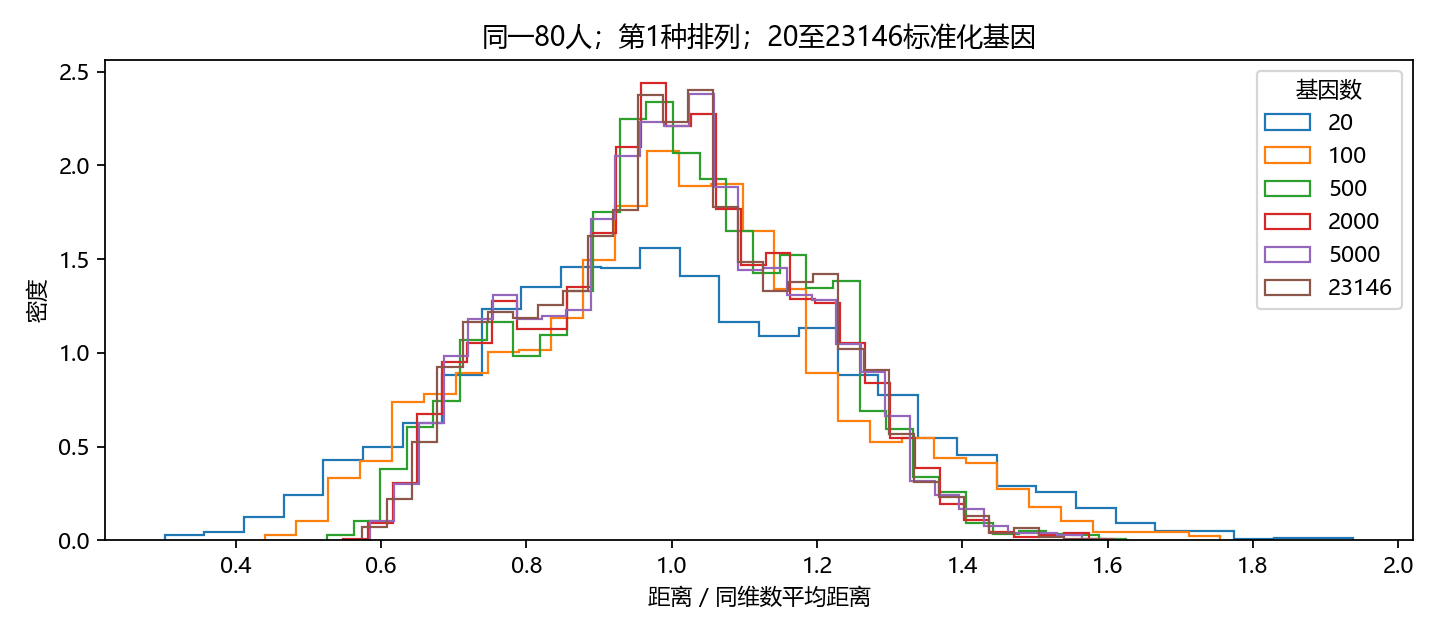

In [3]:
order=np.random.default_rng(SEED+100).permutation(X.shape[1])
fig,ax=plt.subplots(figsize=(9,4))
for k in COUNTS+[X.shape[1]]:
 z=StandardScaler().fit_transform(X[:,order[:k]])
 dd=squareform(pdist(z));np.fill_diagonal(dd,np.inf);near=dd.min(1);np.fill_diagonal(dd,0);far=dd.max(1)
 print(k,"mean",pdist(z).mean(),"near",near.mean(),"far",far.mean(),"contrast",np.mean((far-near)/near))
 ax.hist(pdist(z)/pdist(z).mean(),bins=30,density=True,histtype="step",label=str(k))
ax.set(xlabel="距离 / 同维数平均距离",ylabel="密度",title="同一80人；第1种排列；20至23146标准化基因")
ax.legend(title="基因数")
plot_save("classroom-distances.png")
display(Image(filename=str(OUT/"classroom-distances.png")))

## 课堂 Q3 见过与未见过的患者
同一个参数固定的现成分类器。只用80人拟合标准化与模型；另外40人只记录预测结果。正确比例为正确人数除以本组人数；同时看高危与非高危计数。

In [4]:
def fixed_demo(a,quick=False):
 """Fixed learner and fixed patients. Gene ordering never uses labels.
 Unseen outcomes are descriptive observations and never control model settings.
 """
 tr=a['development'];te=a['test'];X=a['X'];y=a['y'];p=X.shape[1]
 rows=[];predictions=[];fits=[]
 for rep in range(1 if quick else 20):
  order=np.random.default_rng(SEED+100+rep).permutation(p)
  for k in COUNTS+[p]:
   idx=order[:k];sc=StandardScaler().fit(X[tr][:,idx]);zt=sc.transform(X[tr][:,idx])
   model=LogisticRegression(C=1,solver='liblinear',dual=k>len(tr),max_iter=10000,random_state=SEED).fit(zt,y[tr])
   fits.append(dict(repeat=rep+1,p=k,fit_n=int(sc.n_samples_seen_),fit_ids=';'.join(a['ids'][tr]),gene_order_sha256=hashlib.sha256(idx.tobytes()).hexdigest(),mean_sha256=hashlib.sha256(sc.mean_.tobytes()).hexdigest()))
   for group,ix in [('seen',tr),('unseen',te)]:
    pred=model.predict(sc.transform(X[ix][:,idx]));correct=pred==y[ix]
    r=dict(repeat=rep+1,p=k,group=group,n=len(ix),correct=int(correct.sum()),proportion=float(correct.mean()))
    for lab,name in [(1,'high'),(0,'nonhigh')]:
     mask=y[ix]==lab;r[name+'_n']=int(mask.sum());r[name+'_correct']=int(correct[mask].sum());r[name+'_proportion']=float(correct[mask].mean())
    rows.append(r)
    predictions.extend(dict(repeat=rep+1,p=k,group=group,patient=a['ids'][i],target=int(y[i]),prediction=int(pr)) for i,pr in zip(ix,pred))
  print('Fixed gene ordering',rep+1,'complete',flush=True)
 df=pd.DataFrame(rows)
 if quick:return df
 csv('seen-unseen-results.csv',df);csv('seen-unseen-predictions.csv',predictions);csv('fit-audit.csv',fits)
 summary=df.groupby(['p','group']).agg(proportion=('proportion','mean'),minimum=('proportion','min'),maximum=('proportion','max')).reset_index()
 csv('seen-unseen-summary.csv',summary)
 fig,ax=plt.subplots(figsize=(9,4))
 for group,label in [('seen','见过的80人'),('unseen','未见过的40人')]:
  g=summary[summary.group==group];ax.plot(g.p,g.proportion,'o-',label=label);ax.fill_between(g.p,g.minimum,g.maximum,alpha=.15)
 ax.set(xscale='log',xlabel='真实基因数',ylabel='预测正确比例',ylim=(0,1.05),title=f'固定80/40人；20种嵌套基因排列；p=20至{p}；固定分类器')
 ax.legend();plot_save('seen-unseen.png')
 return df
first=fixed_demo(a,quick=True)
print(first.to_string(index=False))

Fixed gene ordering 1 complete
 repeat     p  group  n  correct  proportion  high_n  high_correct  high_proportion  nonhigh_n  nonhigh_correct  nonhigh_proportion
      1    20   seen 80       73      0.9125      27            23         0.851852         53               50            0.943396
      1    20 unseen 40       30      0.7500      14             9         0.642857         26               21            0.807692
      1   100   seen 80       80      1.0000      27            27         1.000000         53               53            1.000000
      1   100 unseen 40       31      0.7750      14             9         0.642857         26               22            0.846154
      1   500   seen 80       80      1.0000      27            27         1.000000         53               53            1.000000
      1   500 unseen 40       35      0.8750      14            13         0.928571         26               22            0.846154
      1  2000   seen 80       80      1.0000 

## 课堂 Q4 Q5 标准化 PCA 与 UMAP
标签不参与降维拟合，只用于画图着色。图上均为同一80人、全部23,146基因。

mean -9.823454395715548e-18 median gene sd 1.0 PCA ratios [0.14493162 0.08263467]


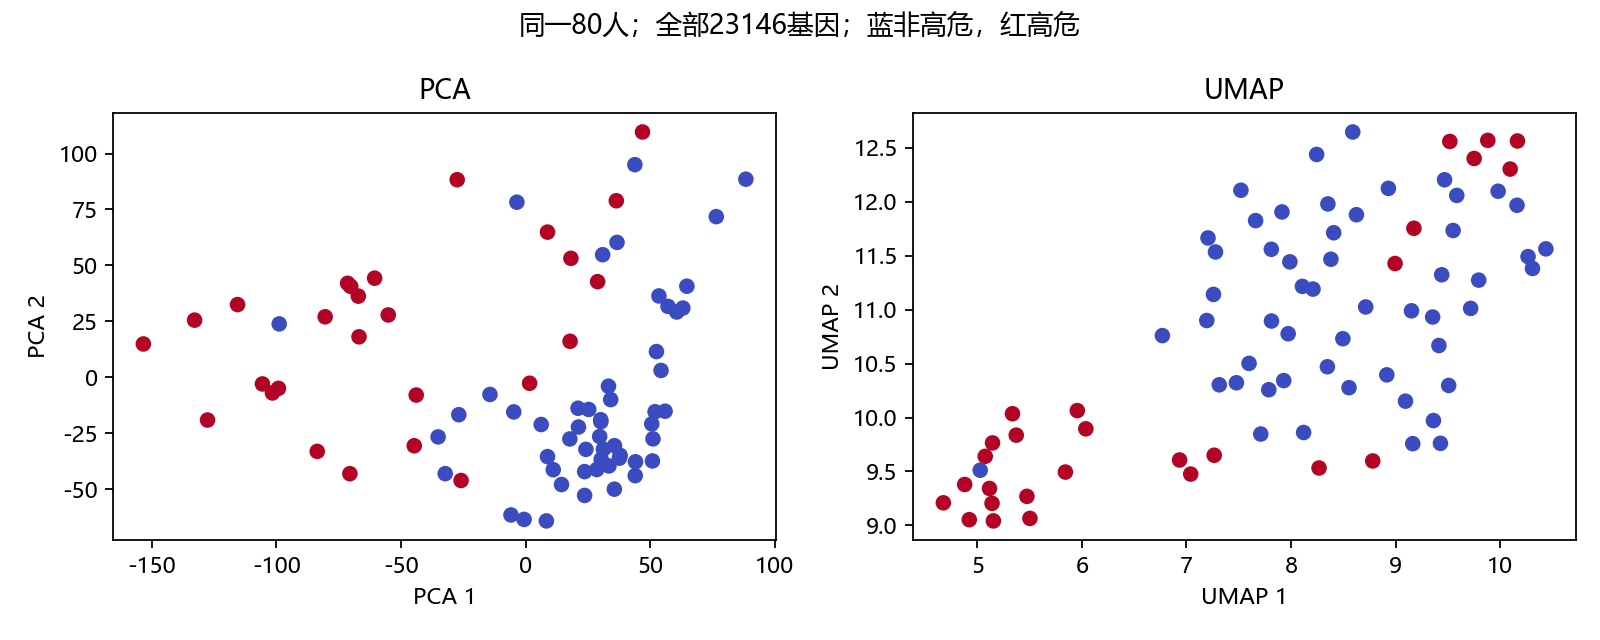

In [5]:
from umap import UMAP
sc=StandardScaler().fit(X);z=sc.transform(X)
pc=PCA(n_components=2,svd_solver="full").fit(z);xy=pc.transform(z)
um=UMAP(n_neighbors=15,min_dist=.1,random_state=SEED,n_jobs=1).fit(z)
print("mean",z.mean(),"median gene sd",np.median(z.std(0)),"PCA ratios",pc.explained_variance_ratio_)
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,label,coords in [(axs[0],"PCA",xy),(axs[1],"UMAP",um.embedding_)]:
 ax.scatter(coords[:,0],coords[:,1],c=y,cmap="coolwarm");ax.set(xlabel=label+" 1",ylabel=label+" 2",title=label)
fig.suptitle("同一80人；全部23146基因；蓝非高危，红高危")
plot_save("classroom-pca-umap.png")
display(Image(filename=str(OUT/"classroom-pca-umap.png")))

## 课堂停止点
填写课堂记录与退出条。完整20排列与参数对照由教师预先执行，按Packet释放。课堂已经观察固定40人的预测结果，不能据此改设置。